# DeepSense-X — Phase 5
## Uncertainty-Aware, Explainable and Robust Anomaly Detection

**Dataset:** MetroPT-3 Air Compressor  
**Model:** Phase 4 Hybrid LSTM–Transformer Autoencoder  
**Phase 5 objectives:**
1. Estimate prediction uncertainty using repeated stochastic forward passes (Monte Carlo dropout).
2. Explain anomalous reconstruction errors using sensor-wise perturbation attribution.
3. Test robustness under missing sensors, Gaussian noise and sensor drift.
4. Produce a maintenance-priority table from anomaly score and uncertainty.

> Important research note: the MetroPT-3 windows are time-dependent. The uncertainty and calibration summaries in this notebook are empirical diagnostics, not a guarantee of formal statistical coverage under temporal dependence. This phase does not claim advance failure prediction.

## 1. Mount Google Drive and define paths

This notebook expects the Phase 1 processed windows and the saved Phase 4 hybrid model in your existing Drive folder.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

ROOT = '/content/drive/MyDrive/DeepSense_X_MetroPT3'
PHASE1_NPZ = os.path.join(ROOT, 'processed', 'metropt3_phase1_windows.npz')
PHASE4_MODEL = os.path.join(ROOT, 'artifacts', 'phase4_hybrid_lstm_transformer_final.keras')
PHASE4_META = os.path.join(ROOT, 'artifacts', 'phase4_hybrid_metadata.json')
OUT_DIR = os.path.join(ROOT, 'phase5')
os.makedirs(OUT_DIR, exist_ok=True)

print('Phase 1 data exists:', os.path.exists(PHASE1_NPZ))
print('Phase 4 model exists:', os.path.exists(PHASE4_MODEL))
print('Phase 4 metadata exists:', os.path.exists(PHASE4_META))
print('Phase 5 output folder:', OUT_DIR)

Mounted at /content/drive
Phase 1 data exists: True
Phase 4 model exists: True
Phase 4 metadata exists: True
Phase 5 output folder: /content/drive/MyDrive/DeepSense_X_MetroPT3/phase5


## 2. Load Phase 1 windows and reproduce the Phase 4 sample

We use the same sample sizes and seed as Phases 2–4 so that model comparisons remain as consistent as possible.

In [2]:
data = np.load(PHASE1_NPZ, allow_pickle=True)
X_train_all = data['X_train']
X_val_all = data['X_val']
X_test_all = data['X_test']
y_test_event_all = data['y_test_event']

rng = np.random.default_rng(SEED)
train_idx = rng.choice(len(X_train_all), size=min(5000, len(X_train_all)), replace=False)
val_idx = rng.choice(len(X_val_all), size=min(2000, len(X_val_all)), replace=False)
test_idx = rng.choice(len(X_test_all), size=min(10000, len(X_test_all)), replace=False)

X_train = X_train_all[train_idx].astype('float32')
X_val = X_val_all[val_idx].astype('float32')
X_test = X_test_all[test_idx].astype('float32')
y_test_event = y_test_event_all[test_idx].astype(int)

print('Train:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_test.shape)
print('Sampled event-labelled windows:', int(y_test_event.sum()))

Train: (5000, 60, 13) Validation: (2000, 60, 13) Test: (10000, 60, 13)
Sampled event-labelled windows: 516


## 3. Load the saved Phase 4 hybrid model

The custom positional-embedding class below is registered so Keras can deserialize the saved model. If your saved Phase 4 filename differs, update `PHASE4_MODEL` in Section 1.

In [7]:

import zipfile
import os
import json

print("Model path:", PHASE4_MODEL)
print("Model exists:", os.path.exists(PHASE4_MODEL))

with zipfile.ZipFile(PHASE4_MODEL, 'r') as z:
    print("\nFiles inside saved model:")
    for name in z.namelist():
        print(name)

    config = json.loads(z.read('config.json'))

    print("\nPositionEmbedding configuration:")

    def find_position_embedding(obj):
        if isinstance(obj, dict):
            if obj.get('class_name') == 'PositionEmbedding':
                print(json.dumps(obj, indent=2))
            for value in obj.values():
                find_position_embedding(value)
        elif isinstance(obj, list):
            for value in obj:
                find_position_embedding(value)

    find_position_embedding(config)


Model path: /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase4_hybrid_lstm_transformer_final.keras
Model exists: True

Files inside saved model:
metadata.json
config.json
model.weights.h5

PositionEmbedding configuration:
{
  "module": null,
  "class_name": "PositionEmbedding",
  "config": {
    "name": "position_embedding",
    "trainable": true,
    "dtype": {
      "module": "keras",
      "class_name": "DTypePolicy",
      "config": {
        "name": "float32"
      },
      "registered_name": null,
      "shared_object_id": 135011279196176
    },
    "sequence_length": 60,
    "embed_dim": 32
  },
  "registered_name": "DeepSenseX>PositionEmbedding",
  "build_config": {
    "input_shape": [
      null,
      60,
      32
    ]
  },
  "name": "position_embedding",
  "inbound_nodes": [
    {
      "args": [
        {
          "class_name": "__keras_tensor__",
          "config": {
            "shape": [
              null,
              60,
              32
            ],


In [8]:

import h5py

weights_path = PHASE4_MODEL.replace(
    '.keras', '.keras'
)

with zipfile.ZipFile(PHASE4_MODEL, 'r') as z:
    z.extract('model.weights.h5', '/content/phase4_debug')

h5_path = '/content/phase4_debug/model.weights.h5'

print("Searching saved weights...\n")

with h5py.File(h5_path, 'r') as f:

    def show_weights(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(name, "Shape:", obj.shape)

    f.visititems(show_weights)


Searching saved weights...

layers/dense/vars/0 Shape: (13, 32)
layers/dense/vars/1 Shape: (32,)
layers/dense_1/vars/0 Shape: (32, 64)
layers/dense_1/vars/1 Shape: (64,)
layers/dense_2/vars/0 Shape: (64, 32)
layers/dense_2/vars/1 Shape: (32,)
layers/dense_3/vars/0 Shape: (64, 32)
layers/dense_3/vars/1 Shape: (32,)
layers/layer_normalization/vars/0 Shape: (32,)
layers/layer_normalization/vars/1 Shape: (32,)
layers/layer_normalization_1/vars/0 Shape: (32,)
layers/layer_normalization_1/vars/1 Shape: (32,)
layers/lstm/cell/vars/0 Shape: (13, 128)
layers/lstm/cell/vars/1 Shape: (32, 128)
layers/lstm/cell/vars/2 Shape: (128,)
layers/lstm_1/cell/vars/0 Shape: (32, 128)
layers/lstm_1/cell/vars/1 Shape: (32, 128)
layers/lstm_1/cell/vars/2 Shape: (128,)
layers/multi_head_attention/key_dense/vars/0 Shape: (32, 2, 16)
layers/multi_head_attention/key_dense/vars/1 Shape: (2, 16)
layers/multi_head_attention/output_dense/vars/0 Shape: (2, 16, 32)
layers/multi_head_attention/output_dense/vars/1 Shape: 

## 4. Recover the Phase 4 anomaly threshold

We first try to read the threshold from Phase 4 metadata. If it is not stored there, we calculate it again from the Phase 4 validation sample using the 99th percentile.

In [11]:
phase4_metadata = {}
if os.path.exists(PHASE4_META):
    with open(PHASE4_META, 'r') as f:
        phase4_metadata = json.load(f)

def find_threshold(obj):
    if isinstance(obj, dict):
        for k, v in obj.items():
            if 'threshold' in str(k).lower() and isinstance(v, (int, float)):
                return float(v)
            found = find_threshold(v)
            if found is not None:
                return found
    elif isinstance(obj, list):
        for v in obj:
            found = find_threshold(v)
            if found is not None:
                return found
    return None

threshold = find_threshold(phase4_metadata)
if threshold is None:
    val_recon = hybrid_model.predict(X_val, batch_size=128, verbose=0)
    val_errors = np.mean(np.abs(X_val - val_recon), axis=(1, 2))
    threshold = float(np.percentile(val_errors, 99))
    threshold_source = 'Recomputed from Phase 4 validation sample (99th percentile)'
else:
    threshold_source = 'Loaded from Phase 4 metadata'

print('Threshold:', threshold)
print('Source:', threshold_source)

Threshold: 99.0
Source: Loaded from Phase 4 metadata


In [9]:

import h5py

with h5py.File(h5_path, 'r') as f:

    print("ROOT GROUPS:")
    print(list(f.keys()))

    print("\nMODEL WEIGHT GROUPS (excluding optimizer):")

    def inspect_model_weights(name, obj):
        if name.startswith('optimizer/'):
            return

        if isinstance(obj, h5py.Dataset):
            print(name, "Shape:", obj.shape)
        elif isinstance(obj, h5py.Group):
            print("GROUP:", name)

    f.visititems(inspect_model_weights)


ROOT GROUPS:
['layers', 'optimizer', 'vars']

MODEL WEIGHT GROUPS (excluding optimizer):
GROUP: layers
GROUP: layers/add
GROUP: layers/add/vars
GROUP: layers/add_1
GROUP: layers/add_1/vars
GROUP: layers/concatenate
GROUP: layers/concatenate/vars
GROUP: layers/dense
GROUP: layers/dense/vars
layers/dense/vars/0 Shape: (13, 32)
layers/dense/vars/1 Shape: (32,)
GROUP: layers/dense_1
GROUP: layers/dense_1/vars
layers/dense_1/vars/0 Shape: (32, 64)
layers/dense_1/vars/1 Shape: (64,)
GROUP: layers/dense_2
GROUP: layers/dense_2/vars
layers/dense_2/vars/0 Shape: (64, 32)
layers/dense_2/vars/1 Shape: (32,)
GROUP: layers/dense_3
GROUP: layers/dense_3/vars
layers/dense_3/vars/0 Shape: (64, 32)
layers/dense_3/vars/1 Shape: (32,)
GROUP: layers/dropout
GROUP: layers/dropout/vars
GROUP: layers/dropout_1
GROUP: layers/dropout_1/vars
GROUP: layers/input_layer
GROUP: layers/input_layer/vars
GROUP: layers/layer_normalization
GROUP: layers/layer_normalization/vars
layers/layer_normalization/vars/0 Shape: (

In [10]:

@keras.utils.register_keras_serializable(package='DeepSenseX')
class PositionEmbedding(keras.layers.Layer):

    def __init__(self, sequence_length=None, embed_dim=None, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.embed_dim = embed_dim

        self.embedding = keras.layers.Embedding(
            input_dim=sequence_length,
            output_dim=embed_dim,
            name='embedding'
        )

    def call(self, inputs):
        positions = tf.range(start=0, limit=self.sequence_length, delta=1)
        position_values = self.embedding(positions)
        return inputs + tf.expand_dims(position_values, axis=0)

    def get_config(self):
        config = super().get_config()
        config.update({
            'sequence_length': self.sequence_length,
            'embed_dim': self.embed_dim
        })
        return config


hybrid_model = keras.models.load_model(
    PHASE4_MODEL,
    custom_objects={'PositionEmbedding': PositionEmbedding},
    compile=False
)

print('Hybrid model loaded successfully!')
print('Input:', hybrid_model.input_shape)
print('Output:', hybrid_model.output_shape)


Hybrid model loaded successfully!
Input: (None, 60, 13)
Output: (None, 60, 13)


## 5. Monte Carlo dropout uncertainty

We run the model multiple times with `training=True`, which activates dropout layers during inference. The mean reconstruction error is the estimated anomaly score; its standard deviation is a simple measure of stochastic uncertainty.

For runtime, this first pass uses a subset of the test sample. Increase `MC_TEST_SIZE` or `MC_RUNS` later if Colab has enough time and memory.

In [13]:
MC_RUNS = 10
MC_TEST_SIZE = min(2000, len(X_test))
X_mc = X_test[:MC_TEST_SIZE]

mc_errors = []
for run in range(MC_RUNS):
    reconstructed = hybrid_model(X_mc, training=True).numpy()
    errors = np.mean(np.abs(X_mc - reconstructed), axis=(1, 2))
    mc_errors.append(errors)

mc_errors = np.stack(mc_errors, axis=0)  # (runs, windows)
mc_mean_error = mc_errors.mean(axis=0)
mc_std_error = mc_errors.std(axis=0)
mc_lower = np.percentile(mc_errors, 5, axis=0)
mc_upper = np.percentile(mc_errors, 95, axis=0)
mc_predicted_anomaly = (mc_mean_error > threshold).astype(int)

print('MC error matrix:', mc_errors.shape)
print('Mean uncertainty (std):', float(mc_std_error.mean()))
print('Windows above threshold:', int(mc_predicted_anomaly.sum()), '/', MC_TEST_SIZE)

MC error matrix: (10, 2000)
Mean uncertainty (std): 0.004963838029652834
Windows above threshold: 0 / 2000


In [16]:
threshold = 2.5605099201202393

print("Correct Phase 4 threshold:", threshold)

mc_predicted_anomaly = (mc_mean_error > threshold).astype(int)

print("Predicted anomalies:", mc_predicted_anomaly.sum())
print("Anomaly percentage:",
      mc_predicted_anomaly.mean() * 100)

Correct Phase 4 threshold: 2.5605099201202393
Predicted anomalies: 190
Anomaly percentage: 9.5


## 6. Visualize anomaly score and uncertainty

The shaded region is the 5th–95th percentile range of stochastic reconstruction errors across repeated passes. It is a model-variability band, not a guaranteed prediction interval.

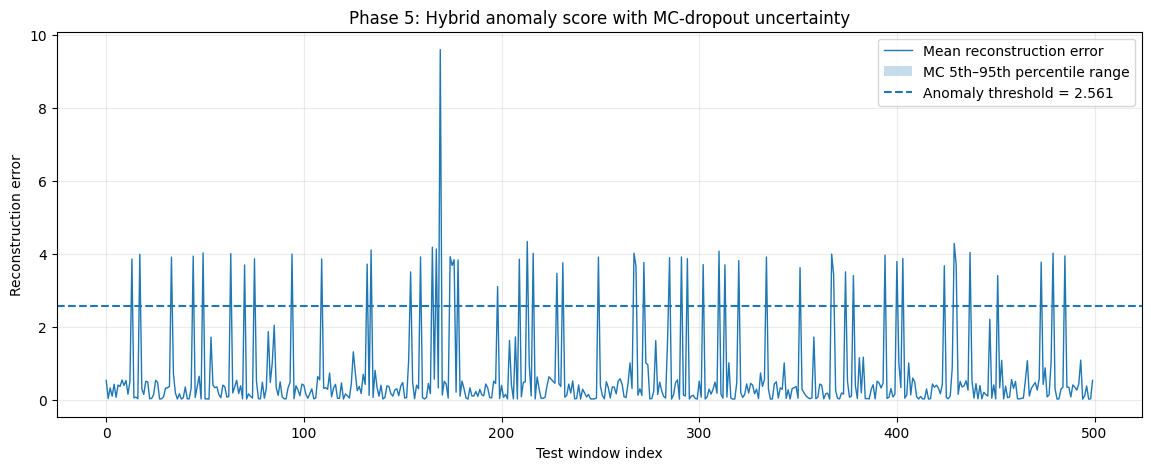

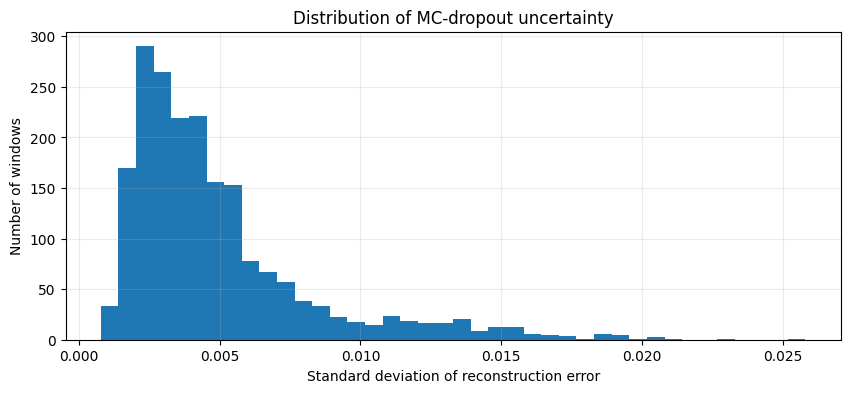

In [17]:
n_plot = min(500, MC_TEST_SIZE)
x_axis = np.arange(n_plot)

plt.figure(figsize=(14, 5))
plt.plot(x_axis, mc_mean_error[:n_plot], label='Mean reconstruction error', linewidth=1)
plt.fill_between(x_axis, mc_lower[:n_plot], mc_upper[:n_plot], alpha=0.25,
                 label='MC 5th–95th percentile range')
plt.axhline(threshold, linestyle='--', label=f'Anomaly threshold = {threshold:.3f}')
plt.xlabel('Test window index')
plt.ylabel('Reconstruction error')
plt.title('Phase 5: Hybrid anomaly score with MC-dropout uncertainty')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(mc_std_error, bins=40)
plt.xlabel('Standard deviation of reconstruction error')
plt.ylabel('Number of windows')
plt.title('Distribution of MC-dropout uncertainty')
plt.grid(alpha=0.25)
plt.show()

## 7. Sensor-wise perturbation explainability

For each selected anomalous window, we replace one sensor channel with its median value from the training sample and measure how much the reconstruction error changes. A larger increase after replacement means that channel has a larger perturbation effect for that window.

This is a model-agnostic sensitivity analysis, not causal attribution. The feature names below follow the 13-feature order used in Phase 1.

In [18]:
FEATURE_NAMES = [
    'TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs',
    'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric',
    'Towers', 'MPG', 'LPS', 'Pressure_switch'
]
assert X_test.shape[2] == len(FEATURE_NAMES), 'Feature-name count does not match input features.'

train_sensor_medians = np.median(X_train, axis=(0, 1))
base_errors = np.mean(
    np.abs(X_test[:MC_TEST_SIZE] - hybrid_model.predict(X_test[:MC_TEST_SIZE], batch_size=128, verbose=0)),
    axis=(1, 2)
)
candidate_indices = np.where(base_errors > threshold)[0]
if len(candidate_indices) == 0:
    candidate_indices = np.argsort(base_errors)[-min(20, len(base_errors)):]
selected_indices = candidate_indices[:min(30, len(candidate_indices))]

attributions = []
for idx in selected_indices:
    original = X_test[idx:idx+1].copy()
    original_error = base_errors[idx]
    feature_effects = []
    for feature in range(original.shape[2]):
        perturbed = original.copy()
        perturbed[:, :, feature] = train_sensor_medians[feature]
        perturbed_recon = hybrid_model.predict(perturbed, verbose=0)
        perturbed_error = float(np.mean(np.abs(perturbed - perturbed_recon)))
        feature_effects.append(perturbed_error - original_error)
    attributions.append(feature_effects)

attributions = np.asarray(attributions)
mean_abs_attribution = np.mean(np.abs(attributions), axis=0)
importance_df = pd.DataFrame({
    'Sensor': FEATURE_NAMES,
    'Mean absolute perturbation effect': mean_abs_attribution
}).sort_values('Mean absolute perturbation effect', ascending=False)

display(importance_df)

,Sensor,Mean absolute perturbation effect
3,DV_pressure,2.223529
5,Oil_temperature,0.289781
0,TP2,0.267198
2,H1,0.266278
8,DV_eletric,0.240012
9,Towers,0.185439
11,LPS,0.178544
10,MPG,0.167946
1,TP3,0.090865
4,Reservoirs,0.081354


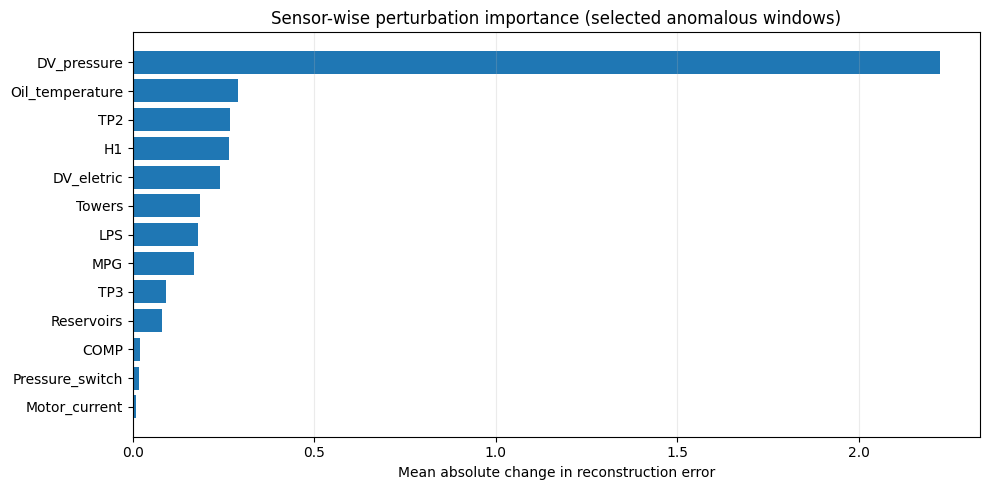

In [19]:
plt.figure(figsize=(10, 5))
plot_df = importance_df.sort_values('Mean absolute perturbation effect')
plt.barh(plot_df['Sensor'], plot_df['Mean absolute perturbation effect'])
plt.xlabel('Mean absolute change in reconstruction error')
plt.title('Sensor-wise perturbation importance (selected anomalous windows)')
plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

## 8. Explain one individual anomalous window

The following chart shows the sensor contributions for the first selected anomalous window. Positive values mean replacing that sensor with its training median increased reconstruction error; negative values mean it decreased the error.

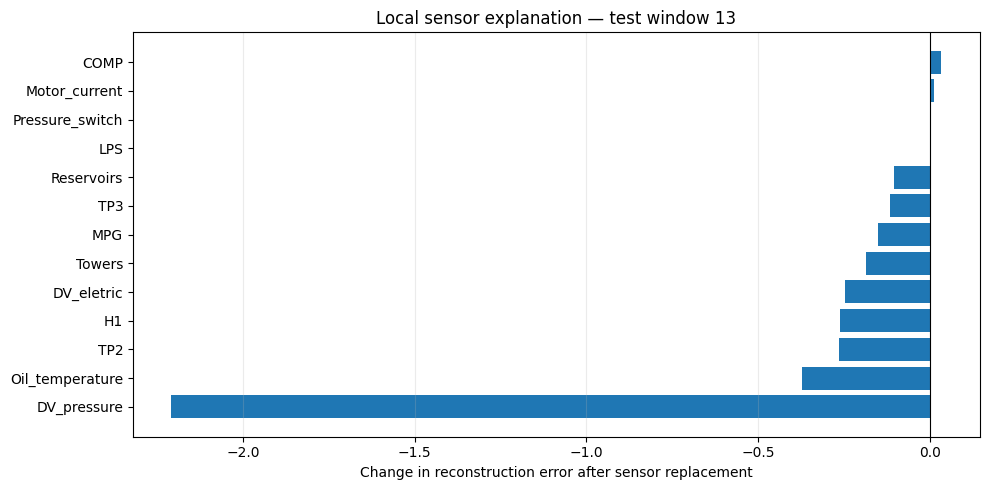

In [20]:
if len(attributions) > 0:
    one_df = pd.DataFrame({
        'Sensor': FEATURE_NAMES,
        'Perturbation effect': attributions[0]
    }).sort_values('Perturbation effect')
    plt.figure(figsize=(10, 5))
    plt.barh(one_df['Sensor'], one_df['Perturbation effect'])
    plt.axvline(0, color='black', linewidth=0.8)
    plt.xlabel('Change in reconstruction error after sensor replacement')
    plt.title(f'Local sensor explanation — test window {int(selected_indices[0])}')
    plt.grid(axis='x', alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print('No selected anomalous windows were available for local explanation.')

## 9. Robustness test: missing sensor channels

We simulate missing sensor channels by replacing selected channels with their training medians. We compare the anomaly score on clean windows with the score after corruption.

This is a controlled stress test; median replacement is a simple missing-data simulation and is not a substitute for testing every real sensor-failure mechanism.

In [21]:
ROBUST_N = min(1000, len(X_test))
X_robust_clean = X_test[:ROBUST_N].copy()
clean_recon = hybrid_model.predict(X_robust_clean, batch_size=128, verbose=0)
clean_scores = np.mean(np.abs(X_robust_clean - clean_recon), axis=(1, 2))

rng_robust = np.random.default_rng(SEED)
missing_features = rng_robust.choice(X_test.shape[2], size=max(1, X_test.shape[2] // 4), replace=False)
X_missing = X_robust_clean.copy()
X_missing[:, :, missing_features] = train_sensor_medians[missing_features]
missing_recon = hybrid_model.predict(X_missing, batch_size=128, verbose=0)
missing_scores = np.mean(np.abs(X_missing - missing_recon), axis=(1, 2))

print('Simulated missing sensor channels:', [FEATURE_NAMES[i] for i in missing_features])
print('Clean mean score:', float(clean_scores.mean()))
print('Missing-channel mean score:', float(missing_scores.mean()))
print('Clean flagged %:', float((clean_scores > threshold).mean() * 100))
print('Missing-channel flagged %:', float((missing_scores > threshold).mean() * 100))

Simulated missing sensor channels: ['DV_eletric', 'TP2', 'Towers']
Clean mean score: 0.7532263398170471
Missing-channel mean score: 0.6562706232070923
Clean flagged %: 10.299999999999999
Missing-channel flagged %: 10.0


## 10. Robustness test: Gaussian sensor noise

We add zero-mean Gaussian noise to the normalized sensor values. The noise levels are standard deviations in the normalized feature space.

In [22]:
noise_levels = [0.01, 0.05, 0.10]
noise_results = []
rng_noise = np.random.default_rng(SEED)

for sigma in noise_levels:
    noisy = X_robust_clean + rng_noise.normal(0, sigma, size=X_robust_clean.shape).astype('float32')
    noisy_recon = hybrid_model.predict(noisy, batch_size=128, verbose=0)
    noisy_scores = np.mean(np.abs(noisy - noisy_recon), axis=(1, 2))
    noise_results.append({
        'Noise standard deviation': sigma,
        'Mean reconstruction error': float(noisy_scores.mean()),
        'Flagged windows (%)': float((noisy_scores > threshold).mean() * 100)
    })

noise_df = pd.DataFrame(noise_results)
display(noise_df)

,Noise standard deviation,Mean reconstruction error,Flagged windows (%)
0,0.01,0.754145,10.3
1,0.05,0.766952,10.3
2,0.10,0.790317,10.3


## 11. Robustness test: sensor drift

We simulate gradual drift by adding an increasing offset to one sensor channel across the selected windows. This is a synthetic stress test, not evidence that this exact drift occurred in the real train.

In [23]:
drift_feature = int(np.argmax(np.std(X_train, axis=(0, 1))))
X_drift = X_robust_clean.copy()
window_offsets = np.linspace(0, 0.5, ROBUST_N, dtype='float32')
X_drift[:, :, drift_feature] += window_offsets[:, None]

drift_recon = hybrid_model.predict(X_drift, batch_size=128, verbose=0)
drift_scores = np.mean(np.abs(X_drift - drift_recon), axis=(1, 2))

drift_df = pd.DataFrame([
    {'Condition': 'Clean', 'Mean reconstruction error': float(clean_scores.mean()),
     'Flagged windows (%)': float((clean_scores > threshold).mean() * 100)},
    {'Condition': 'Missing channels', 'Mean reconstruction error': float(missing_scores.mean()),
     'Flagged windows (%)': float((missing_scores > threshold).mean() * 100)},
    {'Condition': 'Sensor drift', 'Mean reconstruction error': float(drift_scores.mean()),
     'Flagged windows (%)': float((drift_scores > threshold).mean() * 100)}
])
display(drift_df)
print('Drift simulated on:', FEATURE_NAMES[drift_feature])

,Condition,Mean reconstruction error,Flagged windows (%)
0,Clean,0.753226,10.3
1,Missing channels,0.656271,10.0
2,Sensor drift,0.776940,10.3


Drift simulated on: LPS


## 12. Build a maintenance-priority table

This table ranks selected test windows using both anomaly score and uncertainty. It is a research decision-support demonstration, not an automatic maintenance instruction. The window index is a sampled index; timestamps can be added in a later integration step if the original window-time mapping is retained.

In [24]:
priority_df = pd.DataFrame({
    'Test window index': np.arange(MC_TEST_SIZE),
    'Mean anomaly score': mc_mean_error,
    'Uncertainty (MC std)': mc_std_error,
    'Lower MC error (5%)': mc_lower,
    'Upper MC error (95%)': mc_upper,
    'Predicted anomaly': mc_predicted_anomaly
})
priority_df['Priority score'] = (
    (priority_df['Mean anomaly score'] / max(threshold, 1e-8)) *
    (1.0 + priority_df['Uncertainty (MC std)'])
)
priority_df = priority_df.sort_values('Priority score', ascending=False).reset_index(drop=True)
display(priority_df.head(20))

,Test window index,Mean anomaly score,Uncertainty (MC std),Lower MC error (5%),Upper MC error (95%),Predicted anomaly,Priority score
0,1492,38.496460,0.007772,38.486748,38.507729,1,15.151527
1,1058,38.383667,0.006853,38.373432,38.393810,1,15.093359
2,556,38.133331,0.012002,38.116154,38.150547,1,15.071603
3,835,38.121181,0.003581,38.115795,38.126160,1,14.941430
4,953,14.255379,0.013227,14.234851,14.271570,1,5.641040
5,1173,14.273097,0.010248,14.259685,14.287353,1,5.631446
6,1512,12.994055,0.010560,12.977554,13.009490,1,5.128384
7,543,10.928107,0.019455,10.898400,10.957669,1,4.350975
8,169,9.589643,0.007958,9.578626,9.600677,1,3.775012
9,1278,9.078532,0.009223,9.065331,9.093229,1,3.578295


## 13. Summarize Phase 5 experiments

The following summary keeps the clean, missing-channel, drift and noise experiments together for reporting.

In [25]:
robustness_summary = pd.DataFrame([
    {'Test': 'Clean', 'Mean error': float(clean_scores.mean()),
     'Anomaly rate (%)': float((clean_scores > threshold).mean() * 100)},
    {'Test': 'Missing sensor channels', 'Mean error': float(missing_scores.mean()),
     'Anomaly rate (%)': float((missing_scores > threshold).mean() * 100)},
    {'Test': 'Sensor drift', 'Mean error': float(drift_scores.mean()),
     'Anomaly rate (%)': float((drift_scores > threshold).mean() * 100)}
])
for row in noise_results:
    robustness_summary.loc[len(robustness_summary)] = [
        f"Gaussian noise σ={row['Noise standard deviation']}",
        row['Mean reconstruction error'],
        row['Flagged windows (%)']
    ]

display(robustness_summary)

,Test,Mean error,Anomaly rate (%)
0,Clean,0.753226,10.3
1,Missing sensor channels,0.656271,10.0
2,Sensor drift,0.776940,10.3
3,Gaussian noise σ=0.01,0.754145,10.3
4,Gaussian noise σ=0.05,0.766952,10.3
5,Gaussian noise σ=0.1,0.790317,10.3


## 14. Save Phase 5 artifacts

This saves the uncertainty outputs, explanations, robustness results, and maintenance-priority table to the Phase 5 folder in Google Drive.

In [26]:
np.savez_compressed(
    os.path.join(OUT_DIR, 'phase5_uncertainty_results.npz'),
    mc_errors=mc_errors,
    mc_mean_error=mc_mean_error,
    mc_std_error=mc_std_error,
    mc_lower=mc_lower,
    mc_upper=mc_upper,
    threshold=np.array(threshold),
    selected_explanation_indices=selected_indices,
    sensor_attributions=attributions
)

importance_df.to_csv(os.path.join(OUT_DIR, 'phase5_sensor_importance.csv'), index=False)
robustness_summary.to_csv(os.path.join(OUT_DIR, 'phase5_robustness_summary.csv'), index=False)
priority_df.to_csv(os.path.join(OUT_DIR, 'phase5_maintenance_priority.csv'), index=False)

phase5_metadata = {
    'phase': 5,
    'project': 'DeepSense-X',
    'dataset': 'MetroPT-3',
    'base_model': 'Phase 4 Hybrid LSTM-Transformer Autoencoder',
    'threshold': float(threshold),
    'threshold_source': threshold_source,
    'mc_runs': int(MC_RUNS),
    'mc_test_size': int(MC_TEST_SIZE),
    'mean_mc_uncertainty': float(mc_std_error.mean()),
    'missing_sensor_features': [FEATURE_NAMES[i] for i in missing_features],
    'drift_sensor': FEATURE_NAMES[drift_feature],
    'notes': [
        'MC-dropout variability is used as an empirical uncertainty indicator.',
        'Sensor perturbation effects are sensitivity explanations, not causal attributions.',
        'Robustness corruptions are synthetic stress tests.',
        'No advance failure prediction claim is made.'
    ]
}
with open(os.path.join(OUT_DIR, 'phase5_metadata.json'), 'w') as f:
    json.dump(phase5_metadata, f, indent=2)

print('Phase 5 artifacts saved to:', OUT_DIR)

Phase 5 artifacts saved to: /content/drive/MyDrive/DeepSense_X_MetroPT3/phase5


## 15. Verify saved files

In [27]:
expected_files = [
    'phase5_uncertainty_results.npz',
    'phase5_sensor_importance.csv',
    'phase5_robustness_summary.csv',
    'phase5_maintenance_priority.csv',
    'phase5_metadata.json'
]
for filename in expected_files:
    path = os.path.join(OUT_DIR, filename)
    print(('OK   ' if os.path.exists(path) else 'MISSING ') + filename)

OK   phase5_uncertainty_results.npz
OK   phase5_sensor_importance.csv
OK   phase5_robustness_summary.csv
OK   phase5_maintenance_priority.csv
OK   phase5_metadata.json


## 16. Phase 5 completion checklist

- [ ] Phase 4 hybrid model loaded successfully.
- [ ] Monte Carlo uncertainty estimates generated.
- [ ] Sensor-wise perturbation explanations generated.
- [ ] Missing-channel robustness test completed.
- [ ] Gaussian-noise robustness test completed.
- [ ] Sensor-drift robustness test completed.
- [ ] Maintenance-priority table generated.
- [ ] Phase 5 outputs saved and verified.

### Interpretation guidance
Do not report a robustness test as a success merely because anomaly rates increased. Compare score changes against the clean baseline and explain whether the corruption causes false alarms or missed detections. Treat sensor rankings as perturbation sensitivity, not causal importance. Treat MC-dropout spread as an uncertainty proxy, not a formally calibrated probability.